## Runner Notebook

In [16]:
part1_expression_file <- "data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt.gz"
part1_annotation_file <- "data/raw/gene_annot.txt.gz"
part1_genotype_dir <- "data/processed/LDREF"
part1_cis_window_bp <- 500000

# Save tab-separated results without quotes or row numbers.
write_part1_table <- function(x, file) {
  write.table(x, file, sep = "\t", quote = FALSE, row.names = FALSE, na = "NA")
}

# Load expression and annotation data, match genes, and define cis windows.
read_part1_inputs <- function(chromosomes = 1:22) {
  # Read the expression table, preserving sample IDs.
  expression <- read.delim(
    gzfile(part1_expression_file),
    check.names = FALSE
  )

  # Sample IDs skip the first 4 columns, which are metadata
  sample_ids <- names(expression)[5:466]

  keep_rows <- !is.na(match(expression$Chr, chromosomes))
  expression <- expression[keep_rows, , drop = FALSE]

  # Strip version suffix from Ensembl gene IDs to match annotation file.
  expression$ensembl_id <- sub("[.][0-9]+$", "", expression$TargetID)

  annotation <- read.delim(gzfile(part1_annotation_file), colClasses = "character")
  required <- c("ID", "CHR", "START", "STOP", "SYM", "TYPE")

  # Keep protein-coding genes on selected chromosomes and the required annotation columns.
  keep_genes <- annotation$TYPE == "protein_coding" & !is.na(match(annotation$CHR, chromosomes))
  genes <- annotation[keep_genes, required, drop = FALSE]

  genes$expression_row <- match(genes$SYM, expression$ensembl_id)
  genes$has_expression <- !is.na(genes$expression_row)

  # TODO: Confirm annotation/BIM genome builds with the professor before the full run.
  genes$gene_start <- as.numeric(genes$START)
  genes$gene_end <- as.numeric(genes$STOP)

  # genes$window_start defines the -500kb cis-SNP for each gene. 
  genes$window_start <- pmax(1, genes$gene_start - part1_cis_window_bp)

  # genes$window_end defines the +500kb cis-SNP for each gene.
  genes$window_end <- genes$gene_end + part1_cis_window_bp

  list(expression = expression, genes = genes, sample_ids = sample_ids)
}

fit_cis_regressions <- function(genotypes, expression, variants) {
  stopifnot(nrow(genotypes) == length(expression), ncol(genotypes) == nrow(variants)) # Not necessary
  
  X <- genotypes
  y <- expression
  observed <- rep(nrow(X), ncol(X))
  mean_by_snp <- colMeans(X, na.rm = TRUE)

  # Keep SNPs where the number of copies of the effect allele differs across individuals.
  has_variance <- apply(X, 2, var) > 0
  if (!any(has_variance)) return(NULL)
  # Build feature vector
  X <- X[, has_variance, drop = FALSE]
  variants <- variants[has_variance, , drop = FALSE]
  observed <- observed[has_variance]
  mean_by_snp <- mean_by_snp[has_variance]

  # Fit to linear regression model for each SNP
  # Extracts the coefficients, standard errors, and p-values.
  fits <- lapply(seq_len(ncol(X)), function(j) {
    fit <- lm(y ~ X[, j])
    coefficients <- summary(fit)$coefficients
    c(
      intercept = coefficients["(Intercept)", "Estimate"],
      beta = coefficients["X[, j]", "Estimate"],
      standard_error = coefficients["X[, j]", "Std. Error"],
      p_value = coefficients["X[, j]", "Pr(>|t|)"]
    )
  })

  # Builds matrix of estimates for each SNP
  estimates <- matrix(
    NA_real_,
    nrow = length(fits),
    ncol = 4,
    dimnames = list(NULL, c("intercept", "beta", "standard_error", "p_value"))
  )

  for (j in seq_along(fits)) {
    estimates[j, ] <- fits[[j]]
  }

  result <- data.frame(snp = variants$SNP, snp_bp = variants$BP,
                       effect_allele = variants$A1, other_allele = variants$A2,
                       beta = estimates[, "beta"],
                       standard_error = estimates[, "standard_error"],
                       p_value = estimates[, "p_value"],
                       intercept = estimates[, "intercept"],
                       n_samples = length(y), n_genotyped = observed,
                       mean_effect_allele_dosage = mean_by_snp, stringsAsFactors = FALSE)
  if (!nrow(result)) {
    return(NULL)
  }
  result
}

map_part1_chromosome <- function(inputs, chromosome, output_dir) {
  # Build the chromosome file prefix and read variant and sample metadata.
  prefix <- file.path(part1_genotype_dir, paste0("1000G.EUR.", chromosome))
  bim <- read.table(paste0(prefix, ".bim"), colClasses = "character",
                    col.names = c("CHR", "SNP", "CM", "BP", "A1", "A2"))
  fam <- read.table(paste0(prefix, ".fam"), colClasses = "character",
                    col.names = c("FID", "IID", "father", "mother", "sex", "phenotype"))
                    
  # Convert SNP positions to numbers for cis-window comparisons.
  bim$BP <- as.numeric(bim$BP)

  # Match genotype and expression samples in genotype file order.
  has_expression_sample <- !is.na(match(fam$IID, inputs$sample_ids))
  shared <- fam$IID[has_expression_sample]

  # Open the genotype matrix and find the rows for the matched samples.
  genos <- BEDMatrix::BEDMatrix(paste0(prefix, ".bed"), simple_names = TRUE)
  genotype_rows <- match(shared, fam$IID)
  # Select genes on this chromosome with expression data.
  genes <- inputs$genes[inputs$genes$CHR == chromosome & inputs$genes$has_expression, , drop = FALSE]

  # Save the family and individual IDs for matched samples.
  write_part1_table(fam[genotype_rows, c("FID", "IID")],
                    file.path(output_dir, paste0("chr", chromosome, "_matched_samples.tsv")))

  # Open the compressed results file and initialize the run summary.
  output_file <- file.path(output_dir, paste0("chr", chromosome, "_cis_eqtl.tsv.gz"))
  con <- gzfile(output_file, "wt")
  on.exit(close(con), add = TRUE)
  first <- TRUE
  top_hits <- list()
  summaries <- vector("list", nrow(genes))
  total_pairs <- 0L
  for (i in seq_len(nrow(genes))) {
    # Find SNPs in the gene's cis window and align expression to genotype rows.
    gene <- genes[i, , drop = FALSE]
    cols <- which(bim$BP >= gene$window_start & bim$BP <= gene$window_end)
    y <- as.numeric(unlist(inputs$expression[gene$expression_row, shared, drop = FALSE],
                            use.names = FALSE))

    # Testing needs 3+ usable expression values that vary.
    # If nearby SNPs exist but none vary in allele count, mark "no_testable_variants".
    stats <- NULL
    status <- if (!length(cols)) "no_cis_variants" else "no_testable_variants"
    if (sum(is.finite(y)) < 3L) {
      status <- "insufficient_expression"
    } else if (var(y[is.finite(y)]) == 0) {
      status <- "constant_expression"
    } else if (length(cols)) {
      X <- as.matrix(genos[genotype_rows, cols, drop = FALSE])
      stats <- fit_cis_regressions(X, y, bim[cols, , drop = FALSE])
      if (!is.null(stats)) status <- "tested"
    }

    # Record how many SNPs were found and tested and why testing was skipped, if applicable.
    if (is.null(stats)) {
      n_tested <- 0
    } else {
      n_tested <- nrow(stats)
    }
    summaries[[i]] <- data.frame(chromosome = chromosome, gene_id = gene$SYM,
                                 gene_symbol = gene$ID, n_cis_variants = length(cols),
                                 n_tested = n_tested, n_expression = sum(is.finite(y)), status = status)

    # Write the association results and save the lowest-p-value SNP for this gene.
    if (n_tested) {
      stats <- cbind(data.frame(chromosome = chromosome, gene_id = gene$SYM,
                                gene_symbol = gene$ID, gene_start = gene$gene_start,
                                gene_end = gene$gene_end, window_start = gene$window_start,
                                window_end = gene$window_end), stats)
      write.table(stats, con, sep = "\t", quote = FALSE, row.names = FALSE,
                  col.names = first, na = "NA")
      first <- FALSE
      total_pairs <- total_pairs + n_tested
      top_hits[[length(top_hits) + 1L]] <- stats[which.min(stats$p_value), , drop = FALSE]
    }
  }

  # Save the per-gene summary and return the top hits and chromosome totals.
  summaries <- do.call(rbind, summaries)
  write_part1_table(summaries, file.path(output_dir, paste0("chr", chromosome, "_gene_summary.tsv")))

  top_hits_table <- if (length(top_hits) > 0) {
    do.call(rbind, top_hits)
  } else {
    NULL
  }

  list(
    top_hits = top_hits_table,
    summary = data.frame(
      chromosome = chromosome,
      n_genotype_samples = nrow(fam),
      n_matched_samples = length(shared),
      n_variants = nrow(bim),
      n_genes_attempted = nrow(genes),
      n_genes_tested = sum(summaries$status == "tested"),
      n_pairs_tested = total_pairs
    )
  )
}

run_part1 <- function(output_dir, chromosomes = 1:22) {
  if (dir.exists(output_dir)) {
    stop("Output directory already exists: ", output_dir,
         ". Choose a new output_dir for a fresh run.")
  }
  
  # Load expression and gene annotations, then create the output directory.
  inputs <- read_part1_inputs(chromosomes)
  dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

  # Creates a list for each chromosome
  # Result is poplated from our map function
  results <- vector("list", length(chromosomes))
  for (i in seq_along(chromosomes)) {
    results[[i]] <- map_part1_chromosome(inputs, chromosomes[i], output_dir)
  }
  
  # Combine the per-chromosome summaries into one table.
  summary <- NULL
  for (chromosome_result in results) {
    summary <- rbind(summary, chromosome_result$summary)
  }

  total_pairs <- sum(summary$n_pairs_tested)
  if (!total_pairs) {
    stop("No associations were tested; inspect per-chromosome gene summaries.")
  }

  top_hits <- NULL
  for (chromosome_result in results) {
    top_hits <- rbind(top_hits, chromosome_result$top_hits)
  }

  write_part1_table(summary, file.path(output_dir, "chromosome_summary.tsv"))
  write_part1_table(top_hits, file.path(output_dir, "top_hit_per_gene.tsv"))
  writeLines("All configured chromosomes completed.", file.path(output_dir, "COMPLETE.txt"))

  print(head(summary))
  invisible(summary)
}

In [13]:
required_results <- c(
  "COMPLETE.txt", "top_hit_per_gene.tsv", "chr22_cis_eqtl.tsv.gz",
  "chr22_matched_samples.tsv"
)
derived_dir <- "data/derived"
candidate_dirs <- c(
  file.path(derived_dir, "part1_path_check_679c41a06a0a"),
  list.files(derived_dir, pattern = "^part1_notebook_chr22_", full.names = TRUE)
)
completed_dirs <- candidate_dirs[vapply(candidate_dirs, function(path) {
  all(file.exists(file.path(path, required_results)))
}, logical(1))]

if (length(completed_dirs)) {
  run_dir <- completed_dirs[[1]]
} else {
  run_dir <- tempfile("part1_notebook_chr22_", tmpdir = derived_dir)
  run_part1(run_dir, chromosomes = 22)
}

### Visualization of results

Here, we selected the highest association score SNP from Chromosome 22. 
From this, we can see that the gene expression increases alongside the increase in the number of copies in the effect allele.

Extracting number of samples and rownames from 1000G.EUR.22.fam...

Extracting number of variants and colnames from 1000G.EUR.22.bim...



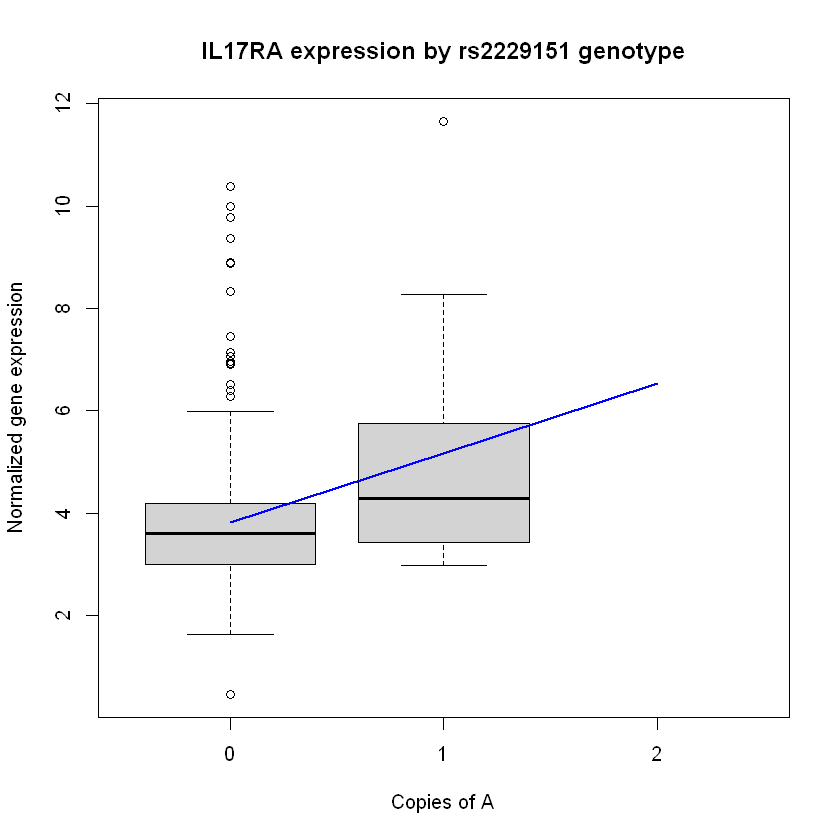

In [17]:
inputs <- read_part1_inputs(chromosomes = 22)
hits <- read.delim(file.path(run_dir, "top_hit_per_gene.tsv"))
snp_result <- hits[hits$gene_symbol == "IL17RA" & hits$snp == "rs2229151", ]

genotype_file <- file.path(part1_genotype_dir, "1000G.EUR.22.bed")
genotypes <- BEDMatrix::BEDMatrix(genotype_file, simple_names = TRUE)

sample_ids <- intersect(rownames(genotypes), inputs$sample_ids)
gene_row <- match(snp_result$gene_id, inputs$expression$ensembl_id)

dosage <- as.numeric(genotypes[sample_ids, snp_result$snp])
expression <- as.numeric(
  unlist(inputs$expression[gene_row, sample_ids], use.names = FALSE)
)

par(bg = "white")
boxplot(
  expression ~ factor(dosage, levels = 0:2),
  at = 0:2,
  xlab = paste("Copies of", snp_result$effect_allele),
  ylab = "Normalized gene expression",
  main = "IL17RA expression by rs2229151 genotype"
)

lines(
  0:2,
  snp_result$intercept + snp_result$beta * (0:2),
  col = "blue",
  lwd = 2
)

### Locus Zoom plot on Chromosome 22

rs2229151, chr 22: 16584953 - 17615693  [253 SNPs]

14 tracks needed to show all genes



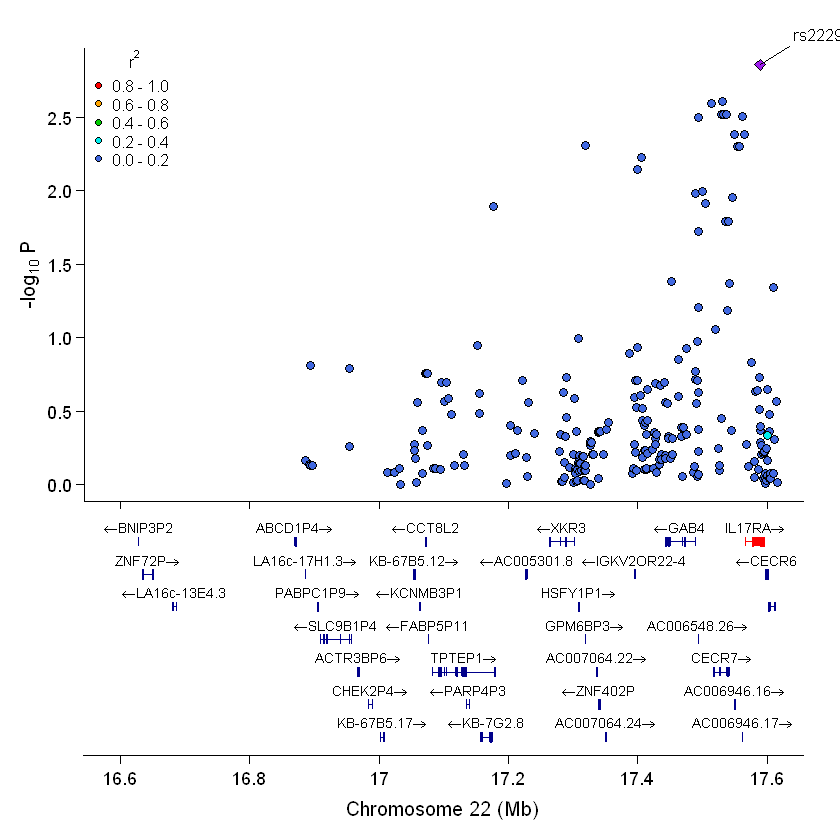

In [18]:
library(EnsDb.Hsapiens.v75)

results <- read.delim(file.path(run_dir, "chr22_cis_eqtl.tsv.gz"))
il17ra <- results[results$gene_symbol == "IL17RA", ]
samples <- read.delim(
  file.path(run_dir, "chr22_matched_samples.tsv"),
  colClasses = "character"
)

# Calculate LD with the SNP that has the lowest raw p-value.
lead_snp <- il17ra$snp[which.min(il17ra$p_value)]
dosages <- as.matrix(genotypes[samples$IID, il17ra$snp, drop = FALSE])
il17ra$ld_r2 <- as.numeric(cor(dosages, dosages[, lead_snp]))^2

il17ra_locus <- locuszoomr::locus(
  data = il17ra,
  seqname = "22",
  xrange = c(il17ra$window_start[1], il17ra$window_end[1]),
  ens_db = "EnsDb.Hsapiens.v75",
  chrom = "chromosome",
  pos = "snp_bp",
  p = "p_value",
  labs = "snp",
  index_snp = lead_snp,
  LD = "ld_r2"
)

par(bg = "white")
locuszoomr::locus_plot(
  il17ra_locus,
  highlight = "IL17RA",
  labels = "index",
  pcutoff = NULL
)